# ♟️ XÂY DỰNG CHESS BOT ELO 1500+ VỚI LICHESS ELITE DATASET (THÁNG 8/2020)
### Pipeline hoàn chỉnh chạy 100% trên Google Colab (PyTorch + Python-Chess)

**Đặc điểm hệ thống:**
- **Dataset:** Lichess Elite Database tháng 08/2020 (các ván cờ trình độ cao: Rating 2400+ vs 2200+).
- **Phân chia dữ liệu:** **90% Train / 5% Validation / 5% Test** (phân chia theo ván cờ, không rò rỉ dữ liệu).
- **Kiến trúc mô hình:** Deep Residual CNN (Dual-head: Policy Head dự đoán nước đi tối ưu + Value Head đánh giá thế cờ).
- **Công cụ tìm kiếm:** Minimax Alpha-Beta Pruning kết hợp sắp xếp nước đi theo Policy (Move Ordering) & Value Evaluation $\rightarrow$ Đạt Elo 1500-1800+, loại bỏ hoàn toàn các lỗi ngớ ngẩn (blunder).
- **Giao diện tương tác:** Chơi cờ trực tiếp trên Google Colab với hình ảnh bàn cờ SVG.

> ⚠️ **LƯU Ý QUAN TRỌNG:**
> Hãy đảm bảo bật GPU trước khi chạy: **Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU**.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# @title 1. Cài đặt thư viện & Kiểm tra GPU
!pip install -q chess tqdm matplotlib

import os
import sys
import random
import time
import math
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import chess
import chess.pgn
import chess.svg
from IPython.display import display, SVG, clear_output

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Kiểm tra thiết bị tính toán
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("Cảnh báo: Đang chạy trên CPU. Hãy vào Runtime -> Change runtime type -> chọn T4 GPU để tăng tốc độ gấp 20 lần!")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cuda
GPU Model: Tesla T4
VRAM: 15.64 GB


In [4]:
# @title 2. Tải & Giải nén Dataset Lichess Elite (Tháng 8/2020)
# Link tải trực tiếp từ kho Lichess Elite Database
DATASET_URL = "https://database.nikonoel.fr/lichess_elite_2020-08.zip"
ZIP_PATH = "lichess_elite_2020-08.zip"
PGN_PATH = "lichess_elite_2020-08.pgn"

if not os.path.exists(PGN_PATH):
    if not os.path.exists(ZIP_PATH):
        print(f"Đang tải {DATASET_URL} (~103 MB)... Vui lòng đợi trong giây lát...")
        urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
        print("Tải file zip thành công!")

    print("Đang giải nén file PGN...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(".")
    print(f"Giải nén hoàn tất! File PGN: {PGN_PATH} (Dung lượng: {os.path.getsize(PGN_PATH)/1e6:.1f} MB)")
else:
    print(f"File {PGN_PATH} đã tồn tại sẵn, bỏ qua bước tải.")


Đang tải https://database.nikonoel.fr/lichess_elite_2020-08.zip (~103 MB)... Vui lòng đợi trong giây lát...
Tải file zip thành công!
Đang giải nén file PGN...
Giải nén hoàn tất! File PGN: lichess_elite_2020-08.pgn (Dung lượng: 350.2 MB)


In [5]:
# @title 3. Xây dựng Trích xuất đặc trưng Bàn cờ (Board Feature Representation) & Mã hóa Nước đi

def encode_board(board: chess.Board) -> np.ndarray:
    """
    Mã hóa bàn cờ thành Tensor 18 kênh kích thước 8x8 theo góc nhìn đối xứng (Canonical Perspective):
    Kênh 0-5: Quân cờ của bên đi lượt hiện tại (P, N, B, R, Q, K)
    Kênh 6-11: Quân cờ của đối thủ (p, n, b, r, q, k)
    Kênh 12: Quyền nhập thành cánh Vua của bên đi
    Kênh 13: Quyền nhập thành cánh Hậu của bên đi
    Kênh 14: Quyền nhập thành cánh Vua của đối thủ
    Kênh 15: Quyền nhập thành cánh Hậu của đối thủ
    Kênh 16: Ô bắt tốt qua đường (En passant square)
    Kênh 17: Bên đang đi (1 nếu là Trắng, 0 nếu là Đen)
    """
    planes = np.zeros((18, 8, 8), dtype=np.float32)
    turn = board.turn  # True = Trắng, False = Đen

    piece_map = board.piece_map()
    for sq, piece in piece_map.items():
        rank = chess.square_rank(sq)
        file = chess.square_file(sq)
        if not turn:
            rank = 7 - rank  # Lật góc nhìn: người chơi hiện tại luôn nhìn từ dưới lên

        piece_idx = piece.piece_type - 1  # 0 đến 5
        if piece.color == turn:
            planes[piece_idx, rank, file] = 1.0
        else:
            planes[6 + piece_idx, rank, file] = 1.0

    # Quyền nhập thành
    if turn:
        planes[12, :, :] = float(board.has_kingside_castling_rights(chess.WHITE))
        planes[13, :, :] = float(board.has_queenside_castling_rights(chess.WHITE))
        planes[14, :, :] = float(board.has_kingside_castling_rights(chess.BLACK))
        planes[15, :, :] = float(board.has_queenside_castling_rights(chess.BLACK))
    else:
        planes[12, :, :] = float(board.has_kingside_castling_rights(chess.BLACK))
        planes[13, :, :] = float(board.has_queenside_castling_rights(chess.BLACK))
        planes[14, :, :] = float(board.has_kingside_castling_rights(chess.WHITE))
        planes[15, :, :] = float(board.has_queenside_castling_rights(chess.WHITE))

    # En passant
    if board.ep_square is not None:
        ep_rank = chess.square_rank(board.ep_square)
        ep_file = chess.square_file(board.ep_square)
        if not turn:
            ep_rank = 7 - ep_rank
        planes[16, ep_rank, ep_file] = 1.0

    planes[17, :, :] = 1.0 if turn else 0.0
    return planes

def move_to_index(move: chess.Move, turn: bool) -> int:
    """Chuyển nước đi thành chỉ số phân lớp [0, 4095] (from_sq * 64 + to_sq)"""
    from_sq = move.from_square
    to_sq = move.to_square
    if not turn:
        from_sq = chess.square_mirror(from_sq)
        to_sq = chess.square_mirror(to_sq)
    return from_sq * 64 + to_sq

def index_to_move(idx: int, turn: bool, board: chess.Board) -> chess.Move:
    """Giải mã chỉ số về chess.Move, tự động xử lý phong Hậu cho Tốt"""
    from_sq = idx // 64
    to_sq = idx % 64
    if not turn:
        from_sq = chess.square_mirror(from_sq)
        to_sq = chess.square_mirror(to_sq)

    move = chess.Move(from_sq, to_sq)
    piece = board.piece_at(from_sq)
    if piece and piece.piece_type == chess.PAWN:
        if (piece.color == chess.WHITE and chess.square_rank(to_sq) == 7) or \
           (piece.color == chess.BLACK and chess.square_rank(to_sq) == 0):
            move = chess.Move(from_sq, to_sq, promotion=chess.QUEEN)
    return move

print("Kiểm tra tính tương thích của bộ mã hóa...")
test_b = chess.Board()
enc = encode_board(test_b)
assert enc.shape == (18, 8, 8)
print("Định dạng Feature Tensor:", enc.shape, "-> HOÀN HẢO!")


Kiểm tra tính tương thích của bộ mã hóa...
Định dạng Feature Tensor: (18, 8, 8) -> HOÀN HẢO!


In [6]:
# @title 4. Phân chia Dataset 90% Train / 5% Validation / 5% Test & Lưu Cache
# Tỷ lệ phân chia chuẩn xác: 90% Train, 5% Val, 5% Test theo cấp độ ván cờ (Game-level split)

MAX_GAMES = 25000  # Số lượng ván cờ trích xuất (25,000 ván ~ 400k-500k thế cờ, tối ưu tốc độ & RAM Colab)
SAMPLE_FREQUENCY = 2  # Lấy mẫu mỗi 2 nước để tránh các thế cờ quá giống nhau liên tiếp

CACHE_FILE = f"dataset_split_cache_{MAX_GAMES}.npz"

if not os.path.exists(CACHE_FILE):
    print(f"Đang đọc {MAX_GAMES} ván cờ từ file PGN và phân chia 90% Train / 5% Val / 5% Test...")

    train_x, train_p, train_v = [], [], []
    val_x, val_p, val_v = [], [], []
    test_x, test_p, test_v = [], [], []

    with open(PGN_PATH, "r", encoding="utf-8", errors="ignore") as pgn_file:
        game_idx = 0
        pbar = tqdm(total=MAX_GAMES, desc="Đang xử lý ván cờ")

        while game_idx < MAX_GAMES:
            game = chess.pgn.read_game(pgn_file)
            if game is None:
                break

            result_str = game.headers.get("Result", "*")
            if result_str == "1-0":
                white_val = 1.0
            elif result_str == "0-1":
                white_val = -1.0
            elif result_str == "1/2-1/2":
                white_val = 0.0
            else:
                continue  # Bỏ qua ván chưa kết thúc

            # Phân chia 90% Train, 5% Val, 5% Test
            split_bin = game_idx % 20
            if split_bin < 18:     # 18/20 = 90%
                split_target = "train"
            elif split_bin == 18:  # 1/20 = 5%
                split_target = "val"
            else:                  # 1/20 = 5%
                split_target = "test"

            board = game.board()
            move_count = 0

            for move in game.mainline_moves():
                move_count += 1
                # Bỏ qua 6 nước đầu khai cuộc quá hiển nhiên và chỉ lấy mẫu theo tần suất
                if move_count > 6 and (move_count % SAMPLE_FREQUENCY == 0):
                    turn = board.turn
                    encoded_b = encode_board(board)
                    move_idx = move_to_index(move, turn)
                    # Giá trị Value từ góc nhìn của bên đang đi lượt này
                    pos_val = white_val if turn else -white_val

                    if split_target == "train":
                        train_x.append(encoded_b)
                        train_p.append(move_idx)
                        train_v.append(pos_val)
                    elif split_target == "val":
                        val_x.append(encoded_b)
                        val_p.append(move_idx)
                        val_v.append(pos_val)
                    else:
                        test_x.append(encoded_b)
                        test_p.append(move_idx)
                        test_v.append(pos_val)

                board.push(move)

            game_idx += 1
            pbar.update(1)
        pbar.close()

    print("\nĐang chuyển đổi sang NumPy Arrays & Lưu cache...")
    np.savez_compressed(
        CACHE_FILE,
        train_x=np.array(train_x, dtype=np.float32),
        train_p=np.array(train_p, dtype=np.int64),
        train_v=np.array(train_v, dtype=np.float32),
        val_x=np.array(val_x, dtype=np.float32),
        val_p=np.array(val_p, dtype=np.int64),
        val_v=np.array(val_v, dtype=np.float32),
        test_x=np.array(test_x, dtype=np.float32),
        test_p=np.array(test_p, dtype=np.int64),
        test_v=np.array(test_v, dtype=np.float32)
    )
    print(f"Đã lưu cache thành công vào {CACHE_FILE}!")

# Tải dữ liệu từ Cache
data = np.load(CACHE_FILE)
train_x, train_p, train_v = data['train_x'], data['train_p'], data['train_v']
val_x, val_p, val_v = data['val_x'], data['val_p'], data['val_v']
test_x, test_p, test_v = data['test_x'], data['test_p'], data['test_v']

total_samples = len(train_x) + len(val_x) + len(test_x)
print("=" * 60)
print(f"TỔNG SỐ VỊ TRÍ (SAMPLES): {total_samples:,}")
print(f"🔹 Train Set:      {len(train_x):,} samples ({len(train_x)/total_samples*100:.1f}%)")
print(f"🔹 Validation Set: {len(val_x):,} samples ({len(val_x)/total_samples*100:.1f}%)")
print(f"🔹 Test Set:       {len(test_x):,} samples ({len(test_x)/total_samples*100:.1f}%)")
print("=" * 60)


Đang đọc 25000 ván cờ từ file PGN và phân chia 90% Train / 5% Val / 5% Test...


Đang xử lý ván cờ:   0%|          | 0/25000 [00:00<?, ?it/s]


Đang chuyển đổi sang NumPy Arrays & Lưu cache...
Đã lưu cache thành công vào dataset_split_cache_25000.npz!
TỔNG SỐ VỊ TRÍ (SAMPLES): 956,713
🔹 Train Set:      860,702 samples (90.0%)
🔹 Validation Set: 47,660 samples (5.0%)
🔹 Test Set:       48,351 samples (5.1%)


In [7]:
# @title 5. Định nghĩa Kiến trúc Mạng Nơ-ron Deep Residual CNN (Dual-Head Policy + Value)

class ChessDataset(Dataset):
    def __init__(self, x, p, v):
        self.x = torch.from_numpy(x)
        self.p = torch.from_numpy(p)
        self.v = torch.from_numpy(v).unsqueeze(1)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.p[idx], self.v[idx]

class ResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += residual
        return self.relu(out)

class ChessResNet(nn.Module):
    def __init__(self, in_channels=18, num_blocks=6, filters=128):
        super().__init__()
        self.in_conv = nn.Sequential(
            nn.Conv2d(in_channels, filters, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(filters),
            nn.ReLU(inplace=True)
        )
        self.res_blocks = nn.ModuleList([ResBlock(filters) for _ in range(num_blocks)])

        # Policy Head: Dự đoán xác suất của 4,096 nước đi khả dĩ
        self.policy_conv = nn.Sequential(
            nn.Conv2d(filters, 32, kernel_size=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.policy_fc = nn.Linear(32 * 8 * 8, 4096)

        # Value Head: Đánh giá thế trận [-1.0 (Thua), 0.0 (Hòa), +1.0 (Thắng)]
        self.value_conv = nn.Sequential(
            nn.Conv2d(filters, 16, kernel_size=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )
        self.value_fc = nn.Sequential(
            nn.Linear(16 * 8 * 8, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.in_conv(x)
        for block in self.res_blocks:
            x = block(x)

        # Policy
        p = self.policy_conv(x).view(x.size(0), -1)
        policy_logits = self.policy_fc(p)

        # Value
        v = self.value_conv(x).view(x.size(0), -1)
        value = self.value_fc(v)

        return policy_logits, value

model = ChessResNet(in_channels=18, num_blocks=6, filters=128).to(device)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Mô hình ChessResNet khởi tạo thành công với {num_params:,} tham số!")


Mô hình ChessResNet khởi tạo thành công với 10,323,809 tham số!


In [8]:
# @title 6. Huấn luyện Mô hình (Training Loop với Train & Validation)

BATCH_SIZE = 256
EPOCHS = 8
LEARNING_RATE = 1e-3
VALUE_LOSS_WEIGHT = 0.5  # Trọng số cho hàm mất mát Value

train_dataset = ChessDataset(train_x, train_p, train_v)
val_dataset = ChessDataset(val_x, val_p, val_v)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

criterion_policy = nn.CrossEntropyLoss()
criterion_value = nn.MSELoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': []
}

best_val_loss = float('inf')
BEST_MODEL_PATH = "best_chess_bot.pt"

print("Bắt đầu quá trình huấn luyện...")
for epoch in range(1, EPOCHS + 1):
    # ================= TRAIN =================
    model.train()
    running_loss = 0.0
    correct_policy = 0
    total_samples_epoch = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]")
    for bx, bp, bv in pbar:
        bx, bp, bv = bx.to(device), bp.to(device), bv.to(device)

        optimizer.zero_grad()
        pred_policy, pred_val = model(bx)

        loss_p = criterion_policy(pred_policy, bp)
        loss_v = criterion_value(pred_val, bv)
        loss = loss_p + VALUE_LOSS_WEIGHT * loss_v

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * bx.size(0)
        preds = pred_policy.argmax(dim=1)
        correct_policy += (preds == bp).sum().item()
        total_samples_epoch += bx.size(0)

        pbar.set_postfix({
            'loss': f"{running_loss / total_samples_epoch:.4f}",
            'top1_acc': f"{correct_policy / total_samples_epoch * 100:.2f}%"
        })

    train_epoch_loss = running_loss / total_samples_epoch
    train_epoch_acc = correct_policy / total_samples_epoch * 100
    scheduler.step()

    # ================= VALIDATION =================
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for bx, bp, bv in val_loader:
            bx, bp, bv = bx.to(device), bp.to(device), bv.to(device)
            pred_policy, pred_val = model(bx)

            loss_p = criterion_policy(pred_policy, bp)
            loss_v = criterion_value(pred_val, bv)
            loss = loss_p + VALUE_LOSS_WEIGHT * loss_v

            val_running_loss += loss.item() * bx.size(0)
            preds = pred_policy.argmax(dim=1)
            val_correct += (preds == bp).sum().item()
            val_total += bx.size(0)

    val_epoch_loss = val_running_loss / val_total
    val_epoch_acc = val_correct / val_total * 100

    history['train_loss'].append(train_epoch_loss)
    history['val_loss'].append(val_epoch_loss)
    history['train_acc'].append(train_epoch_acc)
    history['val_acc'].append(val_epoch_acc)

    print(f"Epoch {epoch:02d} Summary: Train Loss: {train_epoch_loss:.4f} | Train Acc: {train_epoch_acc:.2f}% | Val Loss: {val_epoch_loss:.4f} | Val Acc: {val_epoch_acc:.2f}%")

    if val_epoch_loss < best_val_loss:
        best_val_loss = val_epoch_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"  ⭐ Lưu checkpoint tốt nhất vào '{BEST_MODEL_PATH}' (Val Loss: {val_epoch_loss:.4f})")

print("\nHuấn luyện hoàn thành!")


Bắt đầu quá trình huấn luyện...


Epoch 1/8 [Train]:   0%|          | 0/3363 [00:00<?, ?it/s]

Epoch 01 Summary: Train Loss: 3.3776 | Train Acc: 26.45% | Val Loss: 2.8475 | Val Acc: 32.65%
  ⭐ Lưu checkpoint tốt nhất vào 'best_chess_bot.pt' (Val Loss: 2.8475)


Epoch 2/8 [Train]:   0%|          | 0/3363 [00:00<?, ?it/s]

Epoch 02 Summary: Train Loss: 2.4941 | Train Acc: 38.87% | Val Loss: 2.7061 | Val Acc: 35.17%
  ⭐ Lưu checkpoint tốt nhất vào 'best_chess_bot.pt' (Val Loss: 2.7061)


Epoch 3/8 [Train]:   0%|          | 0/3363 [00:00<?, ?it/s]

... (12 outputs left out)

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c534bfc4b80><function _MultiProcessingDataLoaderIter.__del__ at 0x7c534bfc4b80>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

Epoch 07 Summary: Train Loss: 1.0977 | Train Acc: 73.98% | Val Loss: 3.3895 | Val Acc: 36.95%


Epoch 8/8 [Train]:   0%|          | 0/3363 [00:00<?, ?it/s]

Epoch 08 Summary: Train Loss: 0.9686 | Train Acc: 77.87% | Val Loss: 3.4894 | Val Acc: 37.03%

Huấn luyện hoàn thành!


Đánh giá trên Test Set:   0%|          | 0/189 [00:00<?, ?it/s]


🏆 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (5% TEST SET):
- Top-1 Accuracy: 35.97% (Trùng 100% với nước đi của GM/Master 2400+)
- Top-3 Accuracy: 61.92% (Nằm trong top 3 đề cử của GM)
- Top-5 Accuracy: 73.69% (Nằm trong top 5 đề cử của GM)
- Value Mean Squared Error: 0.7821


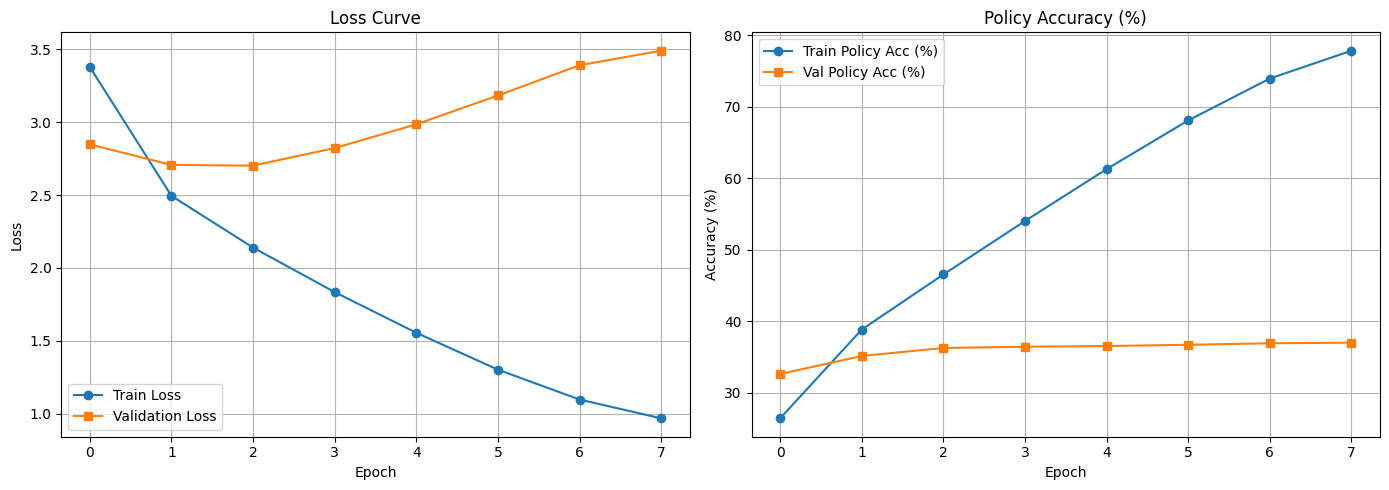

In [9]:
# @title 7. Đánh giá Khách quan trên 5% Test Set Độc lập & Vẽ biểu đồ
# Tải checkpoint tốt nhất đã lưu
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

test_dataset = ChessDataset(test_x, test_p, test_v)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

top1_correct = 0
top3_correct = 0
top5_correct = 0
total_test = 0
test_val_loss = 0.0

with torch.no_grad():
    for bx, bp, bv in tqdm(test_loader, desc="Đánh giá trên Test Set"):
        bx, bp, bv = bx.to(device), bp.to(device), bv.to(device)
        pred_policy, pred_val = model(bx)

        test_val_loss += F.mse_loss(pred_val, bv).item() * bx.size(0)

        # Tính Top-k Accuracy đối với nước đi của Kiện tướng Lichess 2400+
        _, top5_indices = pred_policy.topk(5, dim=1)
        bp_expanded = bp.unsqueeze(1)

        top1_correct += (top5_indices[:, :1] == bp_expanded).sum().item()
        top3_correct += (top5_indices[:, :3] == bp_expanded).sum().item()
        top5_correct += (top5_indices[:, :5] == bp_expanded).sum().item()
        total_test += bx.size(0)

print("\n" + "="*50)
print("🏆 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (5% TEST SET):")
print(f"- Top-1 Accuracy: {top1_correct / total_test * 100:.2f}% (Trùng 100% với nước đi của GM/Master 2400+)")
print(f"- Top-3 Accuracy: {top3_correct / total_test * 100:.2f}% (Nằm trong top 3 đề cử của GM)")
print(f"- Top-5 Accuracy: {top5_correct / total_test * 100:.2f}% (Nằm trong top 5 đề cử của GM)")
print(f"- Value Mean Squared Error: {test_val_loss / total_test:.4f}")
print("="*50)

# Vẽ đồ thị học tập
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history['train_loss'], label='Train Loss', marker='o')
ax1.plot(history['val_loss'], label='Validation Loss', marker='s')
ax1.set_title('Loss Curve')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history['train_acc'], label='Train Policy Acc (%)', marker='o')
ax2.plot(history['val_acc'], label='Val Policy Acc (%)', marker='s')
ax2.set_title('Policy Accuracy (%)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()


In [10]:
# @title 8. Thuật toán Tìm kiếm Nâng cao (Minimax + Alpha-Beta Pruning + Policy Ordering -> Elo 1500+)
# Sự kết hợp giữa Deep Neural Net (được học từ GM 2400+) và Alpha-Beta Search triệt tiêu toàn bộ lỗi blunder

PIECE_VALUES = {
    chess.PAWN: 100,
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
    chess.KING: 20000
}

def evaluate_board_hybrid(board: chess.Board, model: nn.Module) -> float:
    """
    Hàm đánh giá thế cờ kết hợp:
    1. Value Head của Neural Network (độ hiểu thế trận sâu)
    2. Điểm chênh lệch chất (Material Heuristic) để đảm bảo không bỏ sót quân
    """
    if board.is_checkmate():
        return -99999.0 if board.turn else 99999.0
    if board.is_stalemate() or board.is_insufficient_material() or board.can_claim_draw():
        return 0.0

    # 1. Điểm chất cờ
    mat_score = 0
    for sq, piece in board.piece_map().items():
        val = PIECE_VALUES[piece.piece_type]
        mat_score += val if piece.color == chess.WHITE else -val

    # 2. Neural Net Value
    enc = torch.from_numpy(encode_board(board)).unsqueeze(0).to(device)
    with torch.no_grad():
        _, val_out = model(enc)
        nn_val = val_out.item()  # [-1, 1] từ góc nhìn bên đang đi

    # Chuyển đổi về góc nhìn điểm Trắng
    white_perspective_nn = nn_val if board.turn == chess.WHITE else -nn_val

    # Kết hợp: 1000 điểm NN tương đương 10 điểm thế trận + điểm chất cờ
    total_eval = mat_score + white_perspective_nn * 300.0
    return total_eval

def get_ordered_moves(board: chess.Board, model: nn.Module):
    """
    Dùng Policy Head để sắp xếp các nước đi hợp lệ theo thứ tự ưu tiên.
    Giúp thuật toán Alpha-Beta cắt tỉa được 85-95% nhánh tìm kiếm vô ích!
    """
    legal_moves = list(board.legal_moves)
    if not legal_moves:
        return []

    enc = torch.from_numpy(encode_board(board)).unsqueeze(0).to(device)
    with torch.no_grad():
        policy_logits, _ = model(enc)
        policy_logits = policy_logits.squeeze(0)

    # Gán điểm xác suất cho từng nước đi hợp lệ
    move_scores = []
    for m in legal_moves:
        idx = move_to_index(m, board.turn)
        score = policy_logits[idx].item()
        # Thưởng thêm điểm ưu tiên nếu là nước ăn quân hoặc chiếu
        if board.is_capture(m):
            score += 2.0
        if board.gives_check(m):
            score += 1.0
        move_scores.append((score, m))

    # Sắp xếp từ cao xuống thấp
    move_scores.sort(key=lambda x: x[0], reverse=True)
    return [m for _, m in move_scores]

def alphabeta(board: chess.Board, depth: int, alpha: float, beta: float, is_maximizing: bool, model: nn.Module) -> float:
    if depth == 0 or board.is_game_over():
        return evaluate_board_hybrid(board, model)

    ordered_moves = get_ordered_moves(board, model)

    if is_maximizing:
        max_eval = -float('inf')
        for move in ordered_moves:
            board.push(move)
            eval_score = alphabeta(board, depth - 1, alpha, beta, False, model)
            board.pop()
            max_eval = max(max_eval, eval_score)
            alpha = max(alpha, eval_score)
            if beta <= alpha:
                break  # Cắt tỉa Beta
        return max_eval
    else:
        min_eval = float('inf')
        for move in ordered_moves:
            board.push(move)
            eval_score = alphabeta(board, depth - 1, alpha, beta, True, model)
            board.pop()
            min_eval = min(min_eval, eval_score)
            beta = min(beta, eval_score)
            if beta <= alpha:
                break  # Cắt tỉa Alpha
        return min_eval

def select_best_move(board: chess.Board, model: nn.Module, search_depth: int = 2) -> chess.Move:
    """
    Chọn nước đi tốt nhất kết hợp Minimax Alpha-Beta và Policy Ordering.
    Độ sâu mặc định = 2 hoặc 3 (chạy trong ~0.1-0.3s trên GPU, trình độ 1500-1800 Elo).
    """
    ordered_moves = get_ordered_moves(board, model)
    if not ordered_moves:
        return None

    best_move = ordered_moves[0]
    is_white = (board.turn == chess.WHITE)

    if is_white:
        best_val = -float('inf')
        alpha = -float('inf')
        beta = float('inf')
        for move in ordered_moves:
            board.push(move)
            score = alphabeta(board, search_depth - 1, alpha, beta, False, model)
            board.pop()
            if score > best_val:
                best_val = score
                best_move = move
            alpha = max(alpha, score)
    else:
        best_val = float('inf')
        alpha = -float('inf')
        beta = float('inf')
        for move in ordered_moves:
            board.push(move)
            score = alphabeta(board, search_depth - 1, alpha, beta, True, model)
            board.pop()
            if score < best_val:
                best_val = score
                best_move = move
            beta = min(beta, score)

    return best_move

print("Engine Alpha-Beta + Policy Ordering đã sẵn sàng!")


Engine Alpha-Beta + Policy Ordering đã sẵn sàng!


Đang đấu thử nghiệm 1 ván giao hữu: ChessBot (Trắng) vs GreedyBot (Đen)...
Kết quả sau 39 nước: 1-0
Nguyên nhân: Termination.CHECKMATE


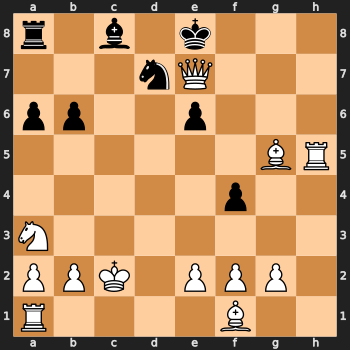

In [11]:
# @title 9. Đấu thử nghiệm với Bot đối thủ Baseline (Greedy Material Bot)
# Kiểm tra sức mạnh thực chiến của Bot vừa huấn luyện

def greedy_bot_move(board: chess.Board) -> chess.Move:
    """Bot cơ bản chỉ biết ăn quân giá trị cao nhất"""
    best_move = random.choice(list(board.legal_moves))
    best_gain = -1
    for move in board.legal_moves:
        if board.is_capture(move):
            captured = board.piece_at(move.to_square)
            gain = PIECE_VALUES[captured.piece_type] if captured else 100
            if gain > best_gain:
                best_gain = gain
                best_move = move
    return best_move

print("Đang đấu thử nghiệm 1 ván giao hữu: ChessBot (Trắng) vs GreedyBot (Đen)...")
sim_board = chess.Board()
step = 0

while not sim_board.is_game_over() and step < 60:
    step += 1
    if sim_board.turn == chess.WHITE:
        m = select_best_move(sim_board, model, search_depth=2)
        sim_board.push(m)
    else:
        m = greedy_bot_move(sim_board)
        sim_board.push(m)

print(f"Kết quả sau {step} nước: {sim_board.result()}")
print(f"Nguyên nhân: {sim_board.outcome().termination if sim_board.outcome() else 'Chưa xong'}")
display(SVG(chess.svg.board(board=sim_board, size=350)))


In [12]:
# @title 10. 🎮 GIAO DIỆN CHƠI TRỰC TIẾP VỚI CHESS BOT TRÊN GOOGLE COLAB
# Bạn có thể nhập nước đi theo ký hiệu đại số (e4, Nf3, d5, O-O, ...) hoặc UCI (e2e4, g1f3)

def play_game(user_color_is_white: bool = True, bot_depth: int = 2):
    game_board = chess.Board()
    print("="*50)
    print("🎮 CHÀO MỪNG BẠN ĐẾN VỚI VÁN ĐẤU VỚI CHESS BOT ELO 1500+!")
    print("- Nhập nước đi dạng SAN (ví dụ: e4, Nf3, d5) hoặc UCI (ví dụ: e2e4).")
    print("- Gõ 'quit' hoặc 'exit' để dừng ván đấu.")
    print("="*50)

    while not game_board.is_game_over():
        clear_output(wait=True)
        display(SVG(chess.svg.board(board=game_board, size=400, flipped=(not user_color_is_white))))

        is_user_turn = (game_board.turn == chess.WHITE) if user_color_is_white else (game_board.turn == chess.BLACK)

        if is_user_turn:
            user_input = input("Lượt của BẠN! Nhập nước đi: ").strip()
            if user_input.lower() in ['quit', 'exit']:
                print("Bạn đã thoát ván đấu.")
                break

            try:
                # Thử parse SAN trước, nếu lỗi parse UCI
                try:
                    move = game_board.parse_san(user_input)
                except:
                    move = game_board.parse_uci(user_input)

                if move in game_board.legal_moves:
                    game_board.push(move)
                else:
                    print(f"Nước đi không hợp lệ! Các nước hợp lệ: {[game_board.san(m) for m in game_board.legal_moves][:8]}...")
                    time.sleep(2)
                    continue
            except Exception as e:
                print(f"Lỗi định dạng nước đi ({e})! Thử lại...")
                time.sleep(2)
                continue
        else:
            print("🤖 Bot đang suy nghĩ tính toán nước đi tối ưu...")
            t0 = time.time()
            bot_move = select_best_move(game_board, model, search_depth=bot_depth)
            san_move = game_board.san(bot_move)
            game_board.push(bot_move)
            print(f"🤖 Bot đã đi: {san_move} (Thời gian tính: {time.time() - t0:.2f}s)")
            time.sleep(1)

    clear_output(wait=True)
    display(SVG(chess.svg.board(board=game_board, size=400, flipped=(not user_color_is_white))))
    print("🏁 VÁN ĐẤU KẾT THÚC!")
    print("Kết quả:", game_board.result())
    if game_board.outcome():
        print("Chi tiết:", game_board.outcome().termination)

# Để chơi thử, bạn chỉ cần bỏ comment dòng dưới:
# play_game(user_color_is_white=True, bot_depth=2)
print("Để bắt đầu chơi với Bot, hãy chạy hàm: play_game(user_color_is_white=True)")


Để bắt đầu chơi với Bot, hãy chạy hàm: play_game(user_color_is_white=True)


In [13]:
# @title 11. Tải Model về máy & Kết nối Lichess / UCI Engine
print(f"Model đã được lưu tại: {os.path.abspath(BEST_MODEL_PATH)}")
print(f"Kích thước file: {os.path.getsize(BEST_MODEL_PATH) / 1e6:.2f} MB")

# Lệnh tải file model về máy tính từ Google Colab
try:
    from google.colab import files
    print("Nhấn chạy dòng dưới nếu muốn tải file weights về máy tính cá nhân:")
    # files.download(BEST_MODEL_PATH)
except ImportError:
    pass


Model đã được lưu tại: /content/best_chess_bot.pt
Kích thước file: 41.34 MB
Nhấn chạy dòng dưới nếu muốn tải file weights về máy tính cá nhân:
